In [1]:
import pandas as pd
import os
parent_dir = '/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/optimized_unexpressed_nosametypeneighbors_withquerycelltype_eval/'
metric_dirs = os.listdir(parent_dir)
sep_files = sorted([os.path.join(parent_dir,x,'cell_type_separation_metrics_layers_pooled.csv') for x in metric_dirs if os.path.exists(os.path.join(parent_dir,x,'cell_type_separation_metrics_layers_pooled.csv'))])
parent_dir = '/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/optimized_unexpressed_nosametypeneighbors_eval/'
metric_dirs = os.listdir(parent_dir)
sep_files += sorted([os.path.join(parent_dir,x,'cell_type_separation_metrics_layers_pooled.csv') for x in metric_dirs if os.path.exists(os.path.join(parent_dir,x,'cell_type_separation_metrics_layers_pooled.csv'))])
sep_df = pd.concat([pd.read_csv(f) for f in sep_files])
# sep_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled/B10_B10/cell_type_separation_metrics_worstadj.csv')
# sep_df['tissue'].iloc[0]
sep_df['dropout']= sep_df['tissue'].apply(lambda x: x.split('_')[-1])

sep_df['input_layer'].unique()

array(['X'], dtype=object)

In [2]:
sep_df['case'].unique()
# sep_df

array(['uncorrected',
       'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.01',
       'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.02',
       'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.05',
       'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.1',
       'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.2',
       'mlp_missing_probability', 'split_missing_counts',
       'admix_probs_optimized_unexpressedgenes_withquerycelltype_X_missing_probability',
       'syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.01',
       'syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.02',
       'syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.05',
       'syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.1',
       'syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.2'],
      dty

['uncorrected', 'syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.1', 'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.1', 'syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.2', 'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.2'] ['uncorrected'
 'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.01'
 'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.02'
 'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.05'
 'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.1'
 'admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.2'
 'mlp_missing_probability' 'split_missing_counts'
 'admix_probs_optimized_unexpressedgenes_withquerycelltype_X_missing_probability'
 'syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.01'
 'syndri_matchedcelltypes_optimized_0_cleaned_

/tmp/ipykernel_3563644/3031559728.py:151: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_3563644/3031559728.py:162: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


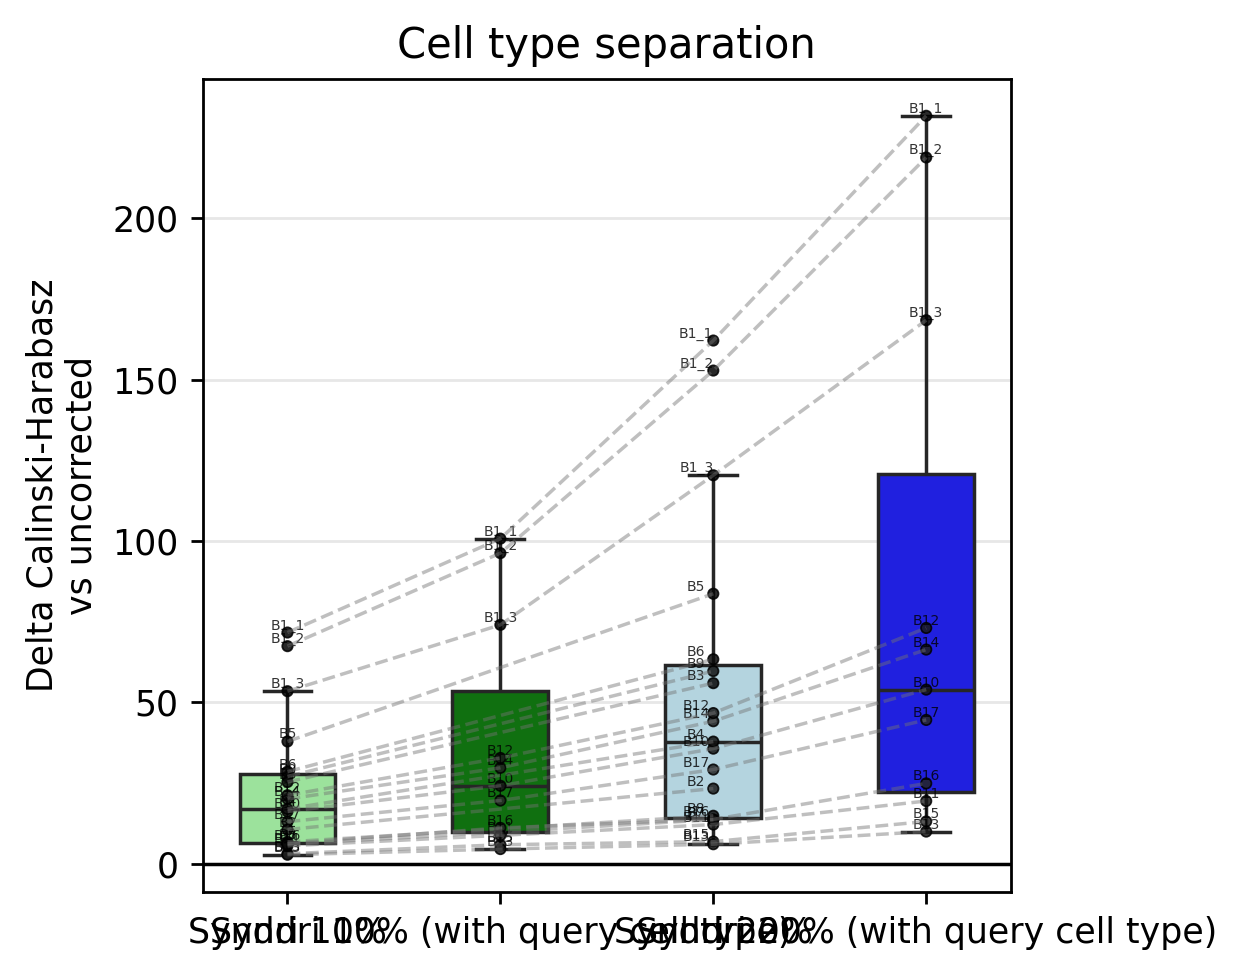

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text

baseline_case = "uncorrected"
method_cases = [
    # "cleaned_admixed_removed_frac_0.01",
    # "cleaned_admixed_removed_frac_0.02",
    # "cleaned_admixed_removed_frac_0.05",
    # "syndri_uncorrected",
    # "mlp_cleaned_removed_frac_0.1",
    "syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.1",
    "admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.1",
    
    # "mlp_cleaned_removed_frac_0.2",
    "syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.2",
    "admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.2",
    # "split",
]

case_labels = {
    # "cleaned_admixed_removed_frac_0.01": "Syndri 1%" ,
    # "cleaned_admixed_removed_frac_0.02": "Syndri 2%",
    # "cleaned_admixed_removed_frac_0.05": "Syndri 5%",
    "uncorrected": "Uncorrected",
    "mlp_cleaned_removed_frac_0.1": "MLP 10%",
    "admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.1": "Syndri 10% (with query cell type)",
    "syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.1":"Syndri 10%",
    "mlp_cleaned_removed_frac_0.2": "MLP 20%",
    "admix_probs_optimized_unexpressedgenes_withquerycelltype_cleaned_removed_frac_0.2": "Syndri 20% (with query cell type)",
    "syndri_matchedcelltypes_optimized_0_cleaned_removed_frac_0.2":"Syndri 20%",
    "split": "SPLIT",
}

metrics = [
    (
        "calinski_harabasz",
        "Cell type separation",
        "Delta Calinski-Harabasz\nvs uncorrected",
    ),
    # (
    #     "davies_bouldin",
    #     "Cluster compactness/separation",
    #     "Delta Davies-Bouldin\nvs uncorrected",
    # ),
    # (
    #     "leiden_adjusted_rand_vs_label",
    #     "Leiden ARI",
    #     "Delta Leiden ARI\nvs uncorrected",
    # ),
    # (
    #     "silhouette_score",
    #     "Silhouette (Cell Type)",
    #     "Delta silhouette score\nvs uncorrected",
    # ),
]

id_cols = ["tissue"]
# if "source_file" in sep_df.columns:
#     id_cols = ["source_file"]
# elif "filename" in sep_df.columns:
#     id_cols = ["filename"]

plot_base = sep_df[
    (sep_df["case"].isin([baseline_case] + method_cases))&
    (sep_df["dropout_fraction"]==0.00)
].copy()

print([baseline_case]+method_cases,sep_df['case'].unique())
plot_base["sample_id"] = plot_base[id_cols[0]].astype(str)
plot_base["tissue"] = plot_base["sample_id"].apply(
    lambda x: x.split("/")[-1].split(".")[0]
)
delta_frames = []

for metric, _, _ in metrics:
    wide = (
        plot_base
        .pivot_table(
            index=["dropout","sample_id", "tissue"],
            columns="case",
            values=metric,
            aggfunc="mean",
        )
        .reset_index()
    )

    for case in method_cases:
        required_cols = [
            "dropout",
            "sample_id",
            "tissue",
            baseline_case,
            case,
        ]

        # Skip a method if it is entirely absent from the current data.
        if case not in wide.columns or baseline_case not in wide.columns:
            continue
        
        tmp = wide[required_cols].copy()
        tmp["case"] = case
        tmp["case_label"] = case_labels[case]
        tmp["metric"] = metric
        tmp["delta"] = tmp[case] - tmp[baseline_case]

        delta_frames.append(
            tmp[
                [
                    "dropout",
                    "sample_id",
                    "tissue",
                    "case",
                    "case_label",
                    "metric",
                    "delta",
                ]
            ]
        )

delta_df = pd.concat(delta_frames, ignore_index=True)

delta_df["case_label"] = pd.Categorical(
    delta_df["case_label"],
    categories=[case_labels[c] for c in method_cases],
    ordered=True,
)

palette = {
    "Syndri 20%": sns.color_palette("Blues", n_colors=4)[-1],
    "SPLIT": "purple",
}

palette = dict(
    zip(
        [case_labels[c] for c in method_cases],
        # sns.color_palette(
        #     "Blues",
        #     n_colors=len(method_cases[:-1]),
        ["lightgreen","green","lightblue","blue","purple"],
    )
)


def plot_metric_delta(ax, data, metric, title, ylabel):
    sub = data[data["metric"] == metric].copy()
    sub = sub.dropna(subset=["delta"])
    # print(sub.head())
    sns.boxplot(    
        data=sub,
        x="case_label",
        y="delta",
        order=[case_labels[c] for c in method_cases],
        palette=palette,
        width=0.45,
        showfliers=False,
        ax=ax,
    )

    sns.stripplot(
        data=sub,
        x="case_label",
        y="delta",
        order=[case_labels[c] for c in method_cases],
        hue="tissue",
        dodge=False,
        jitter=0,
        size=3,
        linewidth=0.5,
        edgecolor="black",
        alpha=0.85,
        ax=ax,
        legend=False,
        color="black",
    )

    x_lookup = {
        label: i
        for i, label in enumerate(
            [case_labels[c] for c in method_cases]
        )
    }

    label_offsets = {
        "Syndri 20%": -0.08,
        "SPLIT": 0.08,
    }

    texts = []

    for _, row in sub.iterrows():
        # print(row["tissue"])

        x = (
            x_lookup[row["case_label"]]
            + label_offsets.get(row["case_label"], 0.0)
        )
        y = row["delta"]

        # if row["tissue"].split('_')[3] == 'B1':
        # print(row['tissue'])
        texts.append(
            ax.text(
                x,
                y,
                "_".join(row["tissue"].split("_")[4:-4]),
                # row['tissue'],
                fontsize=4,
                ha="center",
                va="bottom",
                alpha=0.8,
            )
        )
        # print("_".join(row["tissue"].split("_")[4:-7]))

    # adjust_text(texts,arrowprops=dict(arrowstyle="->", color='red', lw=0.5))

    paired = (
        sub
        .pivot_table(
            index=["dropout","sample_id", "tissue"],
            columns="case_label",
            values="delta",
            aggfunc="mean",
            observed=False,
        )
        .reset_index()
    )

    method_labels = [case_labels[c] for c in method_cases]

    for _, sample in paired.iterrows():
        available_labels = [
            label
            for label in method_labels
            if label in paired.columns and pd.notna(sample[label])
        ]

        if len(available_labels) >= 2:
            xs = [x_lookup[label] for label in available_labels]
            ys = [sample[label] for label in available_labels]

            ax.plot(
                xs,
                ys,
                color="0.45",
                alpha=0.45,
                linewidth=1,
                zorder=5,
                linestyle="--",
            )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(True, axis="y", alpha=0.3)
    ax.set_xticklabels(ax.get_xticklabels(),ha='right',rotation=45)

delta_df['eval_config'] = delta_df['dropout']
eval_configs = delta_df["eval_config"].dropna().unique()

for eval_config in eval_configs:
    config_df = delta_df[
        delta_df["eval_config"] == eval_config
    ].copy()

    fig, axes_grid = plt.subplots(
        1,
        1,
        figsize=(5, 4),
        sharex=True,
        dpi=250,
    )
    axes = [axes_grid]

    for ax, (metric, title, ylabel) in zip(axes, metrics):
        plot_metric_delta(
            ax=ax,
            data=config_df,
            metric=metric,
            title=title,
            ylabel=ylabel,
        )

    # fig.suptitle(
    #     f"Evaluation configuration: {eval_config}",
    #     fontsize=12,
    #     y=1.02,
    # )

    plt.tight_layout()
    plt.show()

/tmp/ipykernel_1386152/1910452574.py:126: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


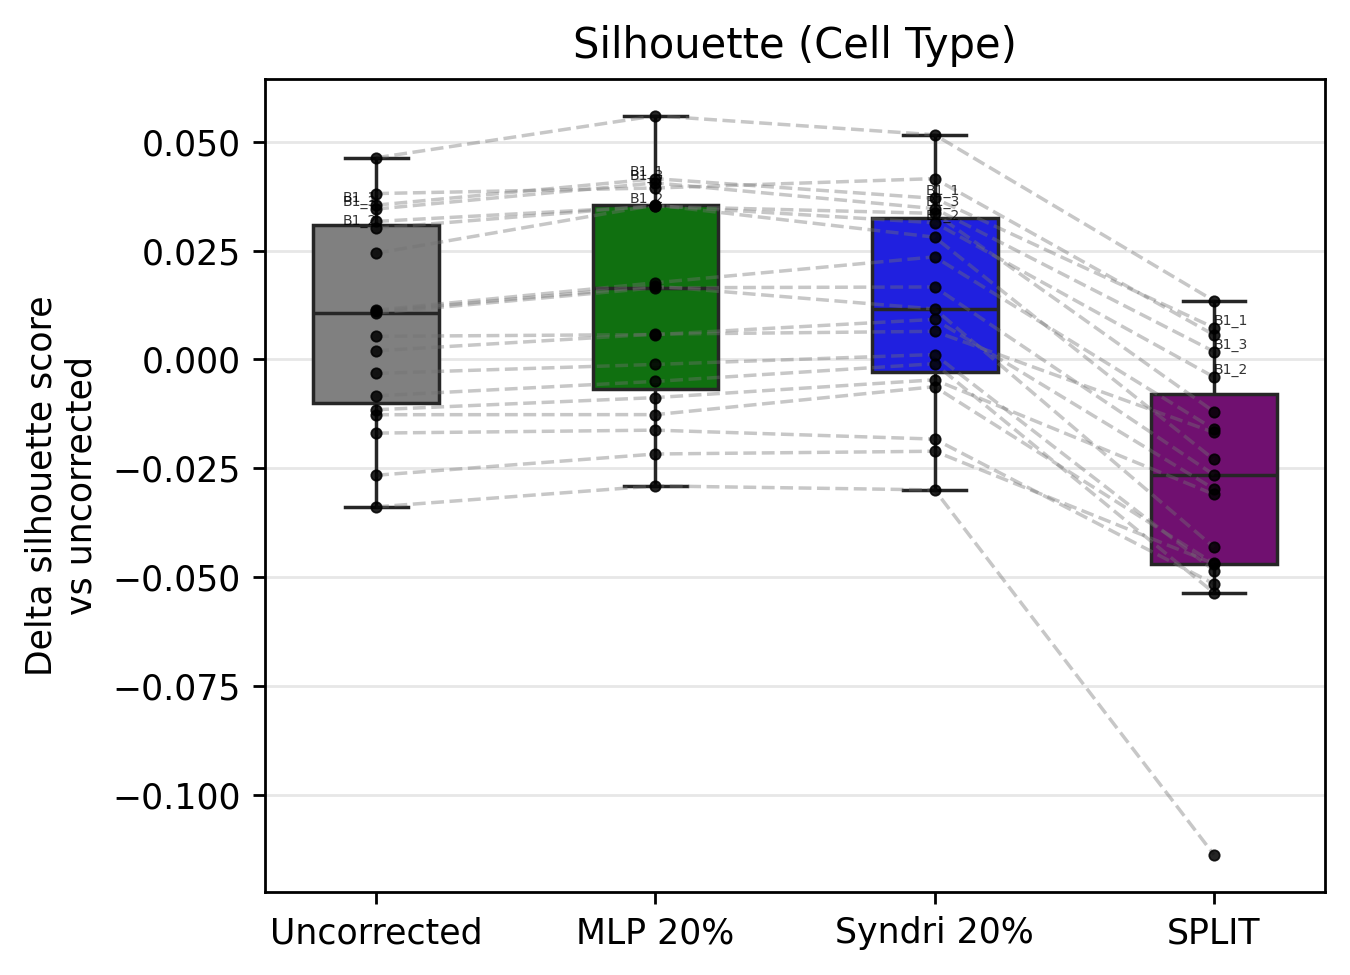

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

baseline_case = "uncorrected"

method_cases = [
    # "mlp_cleaned_removed_frac_0.2",
    "syndri_matchedcelltypes_optimized_X_cleaned_removed_frac_0.2",
    # "split",
]

# Include the baseline when plotting actual values
plot_cases = [baseline_case] + method_cases

case_labels = {
    "uncorrected": "Uncorrected",
    "mlp_cleaned_removed_frac_0.1": "MLP 10%",
    "syndri_cleaned_removed_frac_0.1": "Syndri 10%",
    "mlp_cleaned_removed_frac_0.2": "MLP 20%",
    "syndri_matchedcelltypes_optimized_X_cleaned_removed_frac_0.2": "Syndri 20%",
    "split": "SPLIT",
}

metrics = [
    # (
    #     "calinski_harabasz",
    #     "Cell type separation",
    #     "Calinski–Harabasz score",
    # ),
    # (
    #     "davies_bouldin",
    #     "Cluster compactness/separation",
    #     "Delta Davies-Bouldin\nvs uncorrected",
    # ),
    # (
    #     "leiden_adjusted_rand_vs_label",
    #     "Leiden ARI",
    #     "Delta Leiden ARI\nvs uncorrected",
    # ),
    (
        "silhouette_score",
        "Silhouette (Cell Type)",
        "Delta silhouette score\nvs uncorrected",
    ),
]

id_col = "tissue"

plot_base = sep_df.loc[
    sep_df["case"].isin(plot_cases)
    & sep_df["dropout_fraction"].eq(0.01)
].copy()

plot_base["sample_id"] = plot_base[id_col].astype(str)

plot_base["tissue"] = (
    plot_base["sample_id"]
    .str.split("/")
    .str[-1]
    .str.split(".")
    .str[0]
)

# Average repeated measurements/trials for each tissue, dropout, case,
# and metric before plotting.
value_frames = []

for metric, _, _ in metrics:
    tmp = (
        plot_base
        .groupby(
            [
                "dropout",
                "sample_id",
                "tissue",
                "case",
            ],
            observed=True,
            as_index=False,
        )[metric]
        .mean()
        .rename(columns={metric: "value"})
    )

    tmp["metric"] = metric
    tmp["case_label"] = tmp["case"].map(case_labels)

    value_frames.append(tmp)

value_df = pd.concat(
    value_frames,
    ignore_index=True,
)

method_order = [
    case_labels[case]
    for case in plot_cases
]

value_df["case_label"] = pd.Categorical(
    value_df["case_label"],
    categories=method_order,
    ordered=True,
)

palette = {
    "Uncorrected": "gray",
    "MLP 20%": "green",
    "Syndri 20%": "blue",
    "SPLIT": "purple",
}

def plot_metric_values(
    ax,
    data,
    metric,
    title,
    ylabel,
):
    sub = data.loc[
        data["metric"].eq(metric)
    ].dropna(subset=["value"]).copy()

    sns.boxplot(
        data=sub,
        x="case_label",
        y="value",
        order=method_order,
        palette=palette,
        width=0.45,
        showfliers=False,
        ax=ax,
    )

    sns.stripplot(
        data=sub,
        x="case_label",
        y="value",
        order=method_order,
        jitter=0,
        size=3,
        linewidth=0.5,
        edgecolor="black",
        alpha=0.85,
        color="black",
        legend=False,
        ax=ax,
        zorder=6,
    )

    x_lookup = {
        label: index
        for index, label in enumerate(method_order)
    }

    label_offsets = {
        "Uncorrected": -0.06,
        "MLP 20%": -0.03,
        "Syndri 20%": 0.03,
        "SPLIT": 0.06,
    }

    # Add tissue labels beside points
    for _, row in sub.iterrows():
        tissue_label = "_".join(
            row["tissue"].split("_")[4:-4]
        )

        # Fall back to the complete tissue name if slicing is empty
        if not tissue_label:
            tissue_label = row["tissue"]
        if tissue_label.startswith('B1_'):
            ax.text(
                x_lookup[row["case_label"]]
                + label_offsets.get(row["case_label"], 0),
                row["value"],
                tissue_label,
                fontsize=4,
                ha="center",
                va="bottom",
                alpha=0.8,
                zorder=7,
            )

    # Convert to wide form so each tissue can be connected
    paired = (
        sub
        .pivot_table(
            index=[
                "dropout",
                "sample_id",
                "tissue",
            ],
            columns="case_label",
            values="value",
            aggfunc="mean",
            observed=False,
        )
        .reset_index()
    )

    for _, sample_row in paired.iterrows():
        available_labels = [
            label
            for label in method_order
            if (
                label in paired.columns
                and pd.notna(sample_row[label])
            )
        ]

        if len(available_labels) >= 2:
            xs = [
                x_lookup[label]
                for label in available_labels
            ]

            ys = [
                sample_row[label]
                for label in available_labels
            ]

            ax.plot(
                xs,
                ys,
                color="0.45",
                alpha=0.4,
                linewidth=1,
                linestyle="--",
                zorder=4,
            )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(
        True,
        axis="y",
        alpha=0.3,
    )

value_df["eval_config"] = value_df["dropout"]

eval_configs = (
    value_df["eval_config"]
    .dropna()
    .sort_values()
    .unique()
)

for eval_config in eval_configs:
    config_df = value_df.loc[
        value_df["eval_config"].eq(eval_config)
    ].copy()

    fig, ax = plt.subplots(
        figsize=(5.5, 4),
        dpi=250,
    )

    metric, title, ylabel = metrics[0]

    plot_metric_values(
        ax=ax,
        data=config_df,
        metric=metric,
        title=title,
        ylabel=ylabel,
    )

    # Optional:
    # ax.set_title(
    #     f"{title}\nDropout: {eval_config}"
    # )

    plt.tight_layout()
    plt.show()

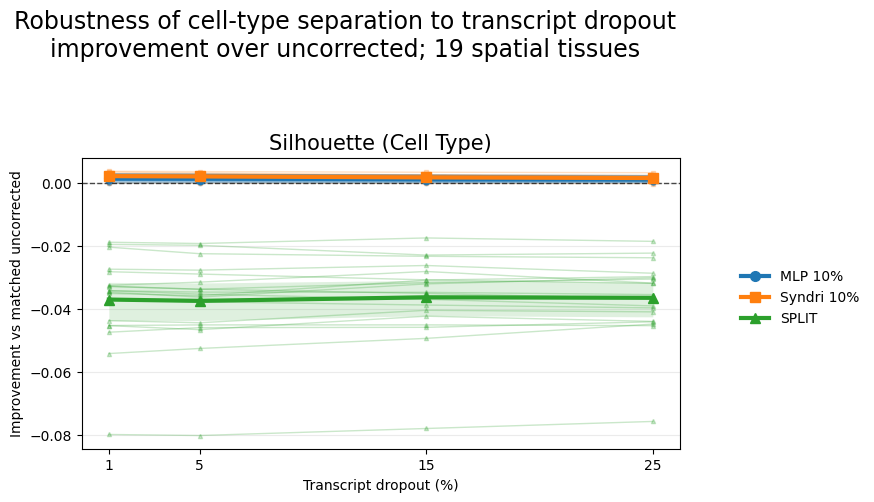

In [25]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ---------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------

TISSUE_COL = "sample_replicate"
TRIAL_COL = "input_layer"
DROPOUT_COL = "dropout"

# This should represent the shared uncorrected counts for each
# tissue/dropout/trial combination.
BASELINE_CASE = "syndri_uncorrected"

METHOD_CASES = {
    "mlp_cleaned_removed_frac_0.1": "MLP 10%",
    "syndri_cleaned_removed_frac_0.1": "Syndri 10%",
    "split": "SPLIT",

    # Add the MLP baseline if desired:
    
}

METRICS = {
    # "calinski_harabasz": {
    #     "title": "Cell type separation",
    #     "direction": 1,
    # },
    # "davies_bouldin": {
    #     "title": "Cluster compactness/separation",
    #     "direction": -1,  # Lower DB is better, so reverse its delta.
    # },
    # "leiden_adjusted_rand_vs_label": {
    #     "title": "Leiden ARI",
    #     "direction": 1,
    # },
    "silhouette_score": {
        "title": "Silhouette (Cell Type)",
        "direction": 1,
    },
}

# "delta":
#     Plot signed improvement over the matched uncorrected data.
#
# "retention":
#     Plot the percentage of the improvement at the lowest available
#     dropout level that remains. When 0pct is added, it will
#     automatically become the reference.
PLOT_MODE = "delta"

SHOW_TRIAL_POINTS = False
N_BOOTSTRAPS = 2000
MIN_TISSUES_FOR_CI = 3
RANDOM_SEED = 42


# ---------------------------------------------------------------------
# Data preparation
# ---------------------------------------------------------------------

def parse_dropout_percent(value):
    """
    Convert values such as '1pct', '15pct', '25%', 0.15, or 15
    into percentages on a 0-100 scale.
    """
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()
    match = re.search(r"[-+]?\d*\.?\d+", text)

    if match is None:
        return np.nan

    number = float(match.group())

    if "pct" in text or "%" in text:
        return number

    # Treat numeric values between 0 and 1 as fractions.
    if 0 <= number <= 1:
        return 100 * number

    return number


metric_cols = list(METRICS)

required_cols = {
    "case",
    TISSUE_COL,
    TRIAL_COL,
    DROPOUT_COL,
    *metric_cols,
}

missing_cols = required_cols.difference(sep_df.columns)

if missing_cols:
    raise KeyError(
        "sep_df is missing the following required columns: "
        f"{sorted(missing_cols)}"
    )


selected_cases = [BASELINE_CASE, *METHOD_CASES.keys()]

work_df = sep_df.loc[
    sep_df["case"].isin(selected_cases)
].copy()

work_df["tissue_id"] = work_df[TISSUE_COL].astype(str)
work_df["trial_id"] = work_df[TRIAL_COL].astype(str)
work_df["dropout_pct"] = work_df[DROPOUT_COL].map(
    parse_dropout_percent
)

work_df = work_df.dropna(subset=["dropout_pct"])


# ---------------------------------------------------------------------
# Construct a matched uncorrected baseline
# ---------------------------------------------------------------------

match_cols = [
    "tissue_id",
    "trial_id",
    "dropout_pct",
]

baseline_df = (
    work_df.loc[work_df["case"].eq(BASELINE_CASE)]
    .groupby(match_cols, observed=True, as_index=False)[metric_cols]
    .mean()
    .rename(
        columns={
            metric: f"{metric}_uncorrected"
            for metric in metric_cols
        }
    )
)

method_df = work_df.loc[
    work_df["case"].isin(METHOD_CASES)
].copy()

method_df["method"] = method_df["case"].map(METHOD_CASES)

method_df = method_df.merge(
    baseline_df,
    on=match_cols,
    how="inner",
    validate="many_to_one",
)

if method_df.empty:
    raise ValueError(
        "No method rows could be matched to uncorrected rows. "
        "Check BASELINE_CASE and the tissue/trial/dropout columns."
    )


# ---------------------------------------------------------------------
# Convert each metric to improvement over uncorrected
# ---------------------------------------------------------------------

long_parts = []

for metric, metric_info in METRICS.items():
    direction = metric_info["direction"]

    metric_part = method_df[
        [
            "tissue_id",
            "trial_id",
            "dropout_pct",
            "method",
            metric,
            f"{metric}_uncorrected",
        ]
    ].copy()

    metric_part["metric"] = metric

    metric_part["improvement"] = direction * (
        metric_part[metric]
        - metric_part[f"{metric}_uncorrected"]
    )

    long_parts.append(
        metric_part[
            [
                "tissue_id",
                "trial_id",
                "dropout_pct",
                "method",
                "metric",
                "improvement",
            ]
        ]
    )

trial_df = pd.concat(long_parts, ignore_index=True)


# Average random trials within each biological tissue.
tissue_df = (
    trial_df
    .groupby(
        [
            "tissue_id",
            "method",
            "metric",
            "dropout_pct",
        ],
        observed=True,
        as_index=False,
    )["improvement"]
    .mean()
)


# ---------------------------------------------------------------------
# Optional conversion to improvement retention
# ---------------------------------------------------------------------

if PLOT_MODE == "delta":
    trial_df["plot_value"] = trial_df["improvement"]
    tissue_df["plot_value"] = tissue_df["improvement"]

    reference_line = 0
    y_label = "Improvement vs matched uncorrected"

elif PLOT_MODE == "change_from_reference":
    reference_keys = [
        "tissue_id",
        "method",
        "metric",
    ]

    # Use the lowest available dropout separately for each
    # tissue/method/metric combination.
    reference_indices = (
        tissue_df
        .groupby(reference_keys, observed=True)["dropout_pct"]
        .idxmin()
    )

    reference_df = (
        tissue_df.loc[
            reference_indices,
            reference_keys + ["dropout_pct", "improvement"],
        ]
        .rename(
            columns={
                "dropout_pct": "reference_dropout_pct",
                "improvement": "reference_improvement",
            }
        )
    )

    tissue_df = tissue_df.merge(
        reference_df,
        on=reference_keys,
        how="left",
        validate="many_to_one",
    )

    # Center each tissue trajectory at its lowest-dropout result.
    tissue_df["plot_value"] = (
        tissue_df["improvement"]
        - tissue_df["reference_improvement"]
    )

    # Center trial points using the corresponding tissue-level
    # lowest-dropout mean.
    trial_df = trial_df.merge(
        reference_df,
        on=reference_keys,
        how="left",
        validate="many_to_one",
    )

    trial_df["plot_value"] = (
        trial_df["improvement"]
        - trial_df["reference_improvement"]
    )

    reference_line = 0
    y_label = "Change in improvement relative to lowest dropout"


# ---------------------------------------------------------------------
# Bootstrap uncertainty across tissues
# ---------------------------------------------------------------------

def bootstrap_tissue_summary(
    data,
    n_bootstraps=2000,
    min_tissues_for_ci=3,
    seed=42,
):
    """
    Calculate the mean and a bootstrap confidence interval across
    biological tissues.

    Random trials have already been averaged within each tissue, so
    tissues—not individual trials—are the independent units.
    """
    rng = np.random.default_rng(seed)
    output_rows = []

    group_cols = [
        "metric",
        "method",
        "dropout_pct",
    ]

    for group_values, group_df in data.groupby(
        group_cols,
        observed=True,
        sort=False,
    ):
        metric, method, dropout_pct = group_values

        values = (
            group_df["plot_value"]
            .dropna()
            .to_numpy(dtype=float)
        )

        n_tissues = len(values)

        if n_tissues == 0:
            continue

        mean_value = values.mean()

        if n_tissues >= min_tissues_for_ci:
            bootstrap_samples = rng.choice(
                values,
                size=(n_bootstraps, n_tissues),
                replace=True,
            )

            bootstrap_means = bootstrap_samples.mean(axis=1)

            ci_low, ci_high = np.quantile(
                bootstrap_means,
                [0.025, 0.975],
            )
        else:
            ci_low = np.nan
            ci_high = np.nan

        output_rows.append(
            {
                "metric": metric,
                "method": method,
                "dropout_pct": dropout_pct,
                "mean": mean_value,
                "ci_low": ci_low,
                "ci_high": ci_high,
                "n_tissues": n_tissues,
            }
        )

    return pd.DataFrame(output_rows)


summary_df = bootstrap_tissue_summary(
    tissue_df,
    n_bootstraps=N_BOOTSTRAPS,
    min_tissues_for_ci=MIN_TISSUES_FOR_CI,
    seed=RANDOM_SEED,
)


# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------

method_order = list(METHOD_CASES.values())
metric_order = list(METRICS)

default_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

method_colors = {
    method: default_colors[i % len(default_colors)]
    for i, method in enumerate(method_order)
}

method_markers = {
    method: marker
    for method, marker in zip(
        method_order,
        ["o", "s", "^", "D", "P"],
    )
}

dropout_values = np.sort(
    tissue_df["dropout_pct"].dropna().unique()
)

# Small offsets keep trial points for different methods visible.
method_offsets = dict(
    zip(
        method_order,
        np.linspace(-0.18, 0.18, len(method_order)),
    )
)

fig, axes = plt.subplots(
    nrows=1,
    ncols=1,
    figsize=(7, 5),
    sharex=True,
)

axes = [axes]

for ax, metric in zip(axes, metric_order):
    metric_tissues = tissue_df.loc[
        tissue_df["metric"].eq(metric)
    ]

    metric_trials = trial_df.loc[
        trial_df["metric"].eq(metric)
    ]

    metric_summary = summary_df.loc[
        summary_df["metric"].eq(metric)
    ]

    # -------------------------------------------------------------
    # Random trials: individual transparent points
    # -------------------------------------------------------------
    if SHOW_TRIAL_POINTS:
        for method in method_order:
            method_trials = metric_trials.loc[
                metric_trials["method"].eq(method)
            ]

            x_values = (
                method_trials["dropout_pct"].to_numpy()
                + method_offsets[method]
            )

            ax.scatter(
                x_values,
                method_trials["plot_value"],
                s=12,
                alpha=0.10,
                color=method_colors[method],
                edgecolors="none",
                zorder=1,
            )

    # -------------------------------------------------------------
    # Tissue trajectories: thin lines through trial means
    # -------------------------------------------------------------
    for (method, tissue_id), tissue_group in (
        metric_tissues
        .groupby(
            ["method", "tissue_id"],
            observed=True,
            sort=False,
        )
    ):
        tissue_group = tissue_group.sort_values("dropout_pct")

        ax.plot(
            tissue_group["dropout_pct"],
            tissue_group["plot_value"],
            color=method_colors[method],
            linewidth=1,
            alpha=0.25,
            marker=method_markers[method],
            markersize=3,
            zorder=2,
        )

    # -------------------------------------------------------------
    # Overall mean and bootstrap CI across tissues
    # -------------------------------------------------------------
    for method in method_order:
        method_summary = (
            metric_summary.loc[
                metric_summary["method"].eq(method)
            ]
            .sort_values("dropout_pct")
        )

        if method_summary.empty:
            continue

        x = method_summary["dropout_pct"].to_numpy()
        y = method_summary["mean"].to_numpy()

        ci_low = method_summary["ci_low"].to_numpy()
        ci_high = method_summary["ci_high"].to_numpy()

        valid_ci = np.isfinite(ci_low) & np.isfinite(ci_high)

        if valid_ci.any():
            ax.fill_between(
                x[valid_ci],
                ci_low[valid_ci],
                ci_high[valid_ci],
                color=method_colors[method],
                alpha=0.15,
                linewidth=0,
                zorder=3,
            )

        ax.plot(
            x,
            y,
            color=method_colors[method],
            marker=method_markers[method],
            markersize=7,
            linewidth=3,
            label=method,
            zorder=4,
        )

    ax.axhline(
        reference_line,
        color="black",
        linewidth=1,
        linestyle="--",
        alpha=0.7,
    )

    ax.set_title(
        METRICS[metric]["title"],
        fontsize=15,
    )

    ax.set_ylabel(y_label)
    ax.grid(axis="y", alpha=0.25)
    ax.set_xticks(dropout_values)

for ax in axes[-2:]:
    ax.set_xlabel("Transcript dropout (%)")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=1,#len(method_order),
    frameon=False,
    bbox_to_anchor=(1.15, 0.5),
)

n_tissues = tissue_df["tissue_id"].nunique()

mode_title = (
    "improvement over uncorrected"
    if PLOT_MODE == "delta"
    else "retention relative to lowest dropout"
)

fig.suptitle(
    "Robustness of cell-type separation to transcript dropout\n"
    f"{mode_title}; {n_tissues} spatial tissues",
    fontsize=17,
    y=0.995,
)

fig.tight_layout(rect=(0, 0, 1, 0.91))

plt.show()

# Optional:
# fig.savefig(
#     "dropout_robustness_metrics.pdf",
#     bbox_inches="tight",
# )

In [15]:
sep_df['case'].unique()

array(['syndri_uncorrected', 'syndri_cleaned_removed_frac_0.01',
       'syndri_cleaned_removed_frac_0.02',
       'syndri_cleaned_removed_frac_0.05',
       'syndri_cleaned_removed_frac_0.1',
       'syndri_cleaned_removed_frac_0.2', 'mlp_uncorrected',
       'mlp_cleaned_removed_frac_0.01', 'mlp_cleaned_removed_frac_0.02',
       'mlp_cleaned_removed_frac_0.05', 'mlp_cleaned_removed_frac_0.1',
       'mlp_cleaned_removed_frac_0.2', 'split'], dtype=object)

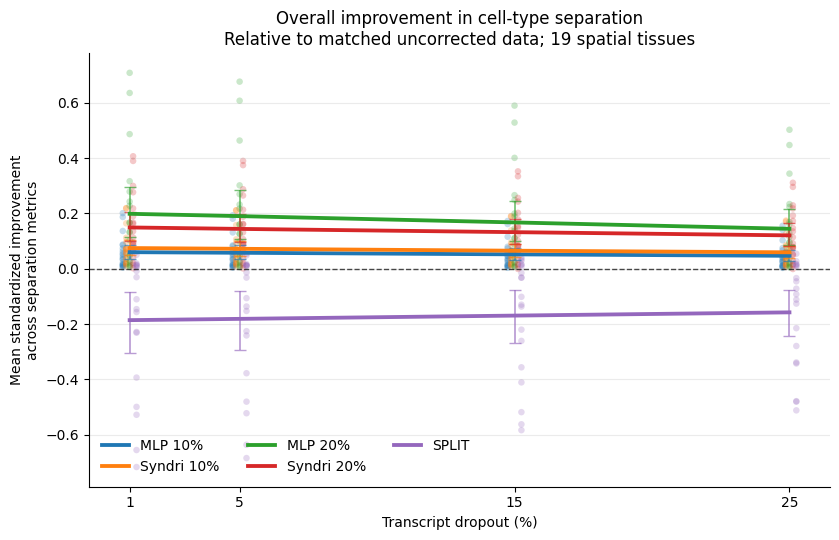

In [6]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ---------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------

TISSUE_COL = "sample_replicate"
TRIAL_COL = "input_layer"
DROPOUT_COL = "dropout"

BASELINE_CASE = "syndri_uncorrected"

METHOD_CASES = {
    "mlp_cleaned_removed_frac_0.1": "MLP 10%",
    "syndri_cleaned_removed_frac_0.1": "Syndri 10%",
    "mlp_cleaned_removed_frac_0.2": "MLP 20%",
    "syndri_cleaned_removed_frac_0.2": "Syndri 20%",
    "split": "SPLIT",
    
}

# Direction is +1 when higher is better and -1 when lower is better.
METRICS = {
    "calinski_harabasz": 1,
    # "davies_bouldin": -1,
    # "leiden_adjusted_rand_vs_label": 1,
    # "silhouette_score": 1,
}

METHOD_ORDER = [
    "MLP 10%",
    "Syndri 10%",
    "MLP 20%",
    "Syndri 20%",
    "SPLIT",
    
]

METHOD_MARKERS = {
    "Syndri 10%": "o",
    "SPLIT": "s",
    "MLP 10%": "^",
}

N_BOOTSTRAPS = 5000
RANDOM_SEED = 42

# Set to True to add faint tissue-level trajectories.
SHOW_TISSUE_LINES = False


# ---------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------

def parse_dropout_percent(value):
    """
    Convert '1pct', '15pct', '25%', 0.15, or 15 to percentage points.
    """
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower()
    match = re.search(r"[-+]?\d*\.?\d+", text)

    if match is None:
        return np.nan

    number = float(match.group())

    if "pct" in text or "%" in text:
        return number

    if 0 <= number <= 1:
        return 100 * number

    return number


def bootstrap_summary(
    tissue_df,
    n_bootstraps=5000,
    seed=42,
):
    """
    Pointwise bootstrap confidence intervals across tissues.

    Each input row should represent one tissue-level value for a
    particular method and dropout fraction.
    """
    rng = np.random.default_rng(seed)
    rows = []

    for (method, dropout_pct), group in tissue_df.groupby(
        ["method", "dropout_pct"],
        observed=True,
        sort=False,
    ):
        values = (
            group["overall_improvement"]
            .dropna()
            .to_numpy(dtype=float)
        )

        if len(values) == 0:
            continue

        mean_value = values.mean()

        if len(values) >= 3:
            bootstrap_values = rng.choice(
                values,
                size=(n_bootstraps, len(values)),
                replace=True,
            )

            bootstrap_means = bootstrap_values.mean(axis=1)

            ci_low, ci_high = np.quantile(
                bootstrap_means,
                [0.025, 0.975],
            )
        else:
            ci_low = np.nan
            ci_high = np.nan

        rows.append(
            {
                "method": method,
                "dropout_pct": dropout_pct,
                "mean": mean_value,
                "ci_low": ci_low,
                "ci_high": ci_high,
                "n_tissues": len(values),
            }
        )

    return pd.DataFrame(rows)


# ---------------------------------------------------------------------
# Prepare matched method and baseline results
# ---------------------------------------------------------------------

metric_cols = list(METRICS)

required_cols = {
    "case",
    TISSUE_COL,
    TRIAL_COL,
    DROPOUT_COL,
    *metric_cols,
}

missing_cols = required_cols.difference(sep_df.columns)

if missing_cols:
    raise KeyError(
        "sep_df is missing required columns: "
        f"{sorted(missing_cols)}"
    )


selected_cases = [
    BASELINE_CASE,
    *METHOD_CASES.keys(),
]

work_df = sep_df.loc[
    sep_df["case"].isin(selected_cases)
].copy()

work_df["tissue_id"] = work_df[TISSUE_COL].astype(str)
work_df["trial_id"] = work_df[TRIAL_COL].astype(str)
work_df["dropout_pct"] = work_df[DROPOUT_COL].map(
    parse_dropout_percent
)

work_df = work_df.dropna(
    subset=[
        "tissue_id",
        "trial_id",
        "dropout_pct",
    ]
)


match_cols = [
    "tissue_id",
    "trial_id",
    "dropout_pct",
]


# One matched uncorrected observation per tissue/trial/dropout.
baseline_df = (
    work_df.loc[
        work_df["case"].eq(BASELINE_CASE)
    ]
    .groupby(
        match_cols,
        observed=True,
        as_index=False,
    )[metric_cols]
    .mean()
)

baseline_df = baseline_df.rename(
    columns={
        metric: f"{metric}_uncorrected"
        for metric in metric_cols
    }
)


method_df = work_df.loc[
    work_df["case"].isin(METHOD_CASES)
].copy()

method_df["method"] = method_df["case"].map(
    METHOD_CASES
)

method_df = method_df.merge(
    baseline_df,
    on=match_cols,
    how="inner",
    validate="many_to_one",
)

if method_df.empty:
    raise ValueError(
        "No method rows matched the uncorrected baseline. "
        "Check the case names and matching columns."
    )


# ---------------------------------------------------------------------
# Compute signed, standardized improvement for each metric
# ---------------------------------------------------------------------

long_parts = []

for metric, direction in METRICS.items():
    baseline_col = f"{metric}_uncorrected"

    metric_df = method_df[
        match_cols
        + [
            "method",
            metric,
            baseline_col,
        ]
    ].copy()

    # Positive always means better than the matched uncorrected result.
    metric_df["raw_improvement"] = direction * (
        metric_df[metric]
        - metric_df[baseline_col]
    )

    # Scale by variability in the uncorrected metric.
    # This preserves zero as "no improvement."
    metric_scale = baseline_df[baseline_col].std(ddof=1)

    if not np.isfinite(metric_scale) or metric_scale <= 1e-12:
        metric_scale = metric_df["raw_improvement"].std(ddof=1)

    if not np.isfinite(metric_scale) or metric_scale <= 1e-12:
        raise ValueError(
            f"Could not calculate a valid scale for {metric}."
        )

    metric_df["standardized_improvement"] = (
        metric_df["raw_improvement"] / metric_scale
    )

    metric_df["metric"] = metric

    long_parts.append(
        metric_df[
            match_cols
            + [
                "method",
                "metric",
                "raw_improvement",
                "standardized_improvement",
            ]
        ]
    )


metric_improvement_df = pd.concat(
    long_parts,
    ignore_index=True,
)


# ---------------------------------------------------------------------
# Average metrics, then trials, within each tissue
# ---------------------------------------------------------------------

# One value per tissue/trial/method/dropout after averaging metrics.
trial_summary_df = (
    metric_improvement_df
    .groupby(
        [
            "tissue_id",
            "trial_id",
            "method",
            "dropout_pct",
        ],
        observed=True,
        as_index=False,
    )["standardized_improvement"]
    .mean()
    .rename(
        columns={
            "standardized_improvement": "overall_improvement"
        }
    )
)


# One value per tissue/method/dropout after averaging random trials.
tissue_summary_df = (
    trial_summary_df
    .groupby(
        [
            "tissue_id",
            "method",
            "dropout_pct",
        ],
        observed=True,
        as_index=False,
    )["overall_improvement"]
    .mean()
)


# Mean and bootstrap CI across tissues.
summary_df = bootstrap_summary(
    tissue_summary_df,
    n_bootstraps=N_BOOTSTRAPS,
    seed=RANDOM_SEED,
)


# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 5.5))

dropout_values = np.sort(
    tissue_summary_df["dropout_pct"].unique()
)

default_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

method_colors = {
    method: default_colors[i]
    for i, method in enumerate(METHOD_ORDER)
}

method_offsets = {
    method: offset
    for method, offset in zip(
        METHOD_ORDER,
        np.linspace(-0.25, 0.25, len(METHOD_ORDER)),
    )
}

# Individual tissue-level averages
for method in METHOD_ORDER:
    method_tissues = tissue_summary_df.loc[
        tissue_summary_df["method"].eq(method)
    ]

    ax.scatter(
        method_tissues["dropout_pct"] + method_offsets[method],
        method_tissues["overall_improvement"],
        s=22,
        alpha=0.25,
        color=method_colors[method],
        edgecolors="none",
        zorder=1,
    )

# Mean across tissues with 95% bootstrap intervals
for method in METHOD_ORDER:
    method_summary = (
        summary_df.loc[
            summary_df["method"].eq(method)
        ]
        .sort_values("dropout_pct")
    )

    if method_summary.empty:
        continue

    x = method_summary["dropout_pct"].to_numpy()
    y = method_summary["mean"].to_numpy()
    ci_low = method_summary["ci_low"].to_numpy()
    ci_high = method_summary["ci_high"].to_numpy()

    lower_error = y - ci_low
    upper_error = ci_high - y

    valid_ci = (
        np.isfinite(lower_error)
        & np.isfinite(upper_error)
    )

    ax.plot(
        x,
        y,
        # marker=METHOD_MARKERS[method],
        markersize=7,
        linewidth=2.75,
        color=method_colors[method],
        label=method,
        zorder=3,
    )

    if valid_ci.any():
        ax.errorbar(
            x[valid_ci],
            y[valid_ci],
            yerr=np.vstack([
                lower_error[valid_ci],
                upper_error[valid_ci],
            ]),
            fmt="none",
            capsize=4,
            elinewidth=1.25,
            color=method_colors[method],
            alpha=0.65,
            zorder=2,
        )

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    alpha=0.7,
)

ax.set_xticks(dropout_values)
ax.set_xlabel("Transcript dropout (%)")
ax.set_ylabel(
    "Mean standardized improvement\n"
    "across separation metrics"
)

n_tissues = tissue_summary_df["tissue_id"].nunique()

ax.set_title(
    "Overall improvement in cell-type separation\n"
    f"Relative to matched uncorrected data; {n_tissues} spatial tissues"
)

ax.legend(
    frameon=False,
    ncol=3,
    loc="lower left",
)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()


# Optional:
# fig.savefig(
#     "overall_dropout_robustness.pdf",
#     bbox_inches="tight",
# )